# 02 · Exploratory data analysis

**Programming for AI · Topic 26 · Participant 1 · Nulimu Arey · AAI-2606M**

Use review records for score counts and one text per paper for text-length summaries.

In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
if not (root / "prepare_data.py").is_file():
    raise FileNotFoundError("Open this notebook from the project root or the notebooks directory.")
sys.path.insert(0, str(root))

In [2]:
from IPython.display import Image, display
from src.data_collection import load_sources, pair_reviews
from src.data_eda import FIGURE, label_counts, length_summary, paper_lengths, plot_overview, raw_missingness, review_patterns

sources = load_sources()
reviews = pair_reviews(sources)
missing = raw_missingness(sources)
lengths = paper_lengths(reviews)

## 1. Class balance and missing values

Review scores are three ordered categories. The Moderate class is the majority, and Low has the fewest examples. Check macro-F1 and class-specific recall alongside accuracy. Missing scores remain in the merged corpus and are excluded from supervised training.

In [3]:
display(label_counts(reviews).to_frame("Paired review records"))
display(missing.rename_axis("Source column"))

,Paired review records
label,
Low,44
Moderate,238
High,103
Unlabeled,30


,en,kk
Source column,,
Unnamed: 0,0,0
Title,0,0
Abstract,0,0
Keywords,4,4
CitationCount,224,224
normalized_title,0,0
Review_score,30,30
Review_comment,30,30


## 2. Repeated reviews and different labels

Compare exact duplicates of full source rows after excluding the exported index. Multiple reviews of the same paper are valid observations, even when reviewers disagree. Keep them together at split time.

In [4]:
for language, frame in sources.items():
    duplicates = frame.drop(columns="Unnamed: 0").duplicated().sum()
    print(f"{language.upper()} duplicate full rows excluding source index: {duplicates}")
for metric, count in review_patterns(reviews).items():
    print(f"{metric.capitalize()}: {count}")

EN duplicate full rows excluding source index: 0
KK duplicate full rows excluding source index: 0
Review pairs: 415
Papers: 215
Labeled review pairs: 385
Labeled papers: 185
Papers with repeated labeled reviews: 185
Papers with differing labeled scores: 93


## 3. Text lengths and exploratory figures

Use Unicode word tokens and count each paper once to avoid over-weighting repeated reviews. The IQR rule flags unusual lengths for review. Retain the observed text.

,count,mean,std,min,25%,50%,75%,max,IQR outliers
title_en,215.0,12.1,3.8,6.0,9.5,12.0,14.0,25.0,10
title_kk,215.0,10.1,3.1,4.0,8.0,10.0,12.0,22.0,4
abstract_en,215.0,171.0,63.6,52.0,129.0,164.0,206.0,404.0,4
abstract_kk,215.0,134.9,50.4,43.0,99.5,133.0,165.5,304.0,2


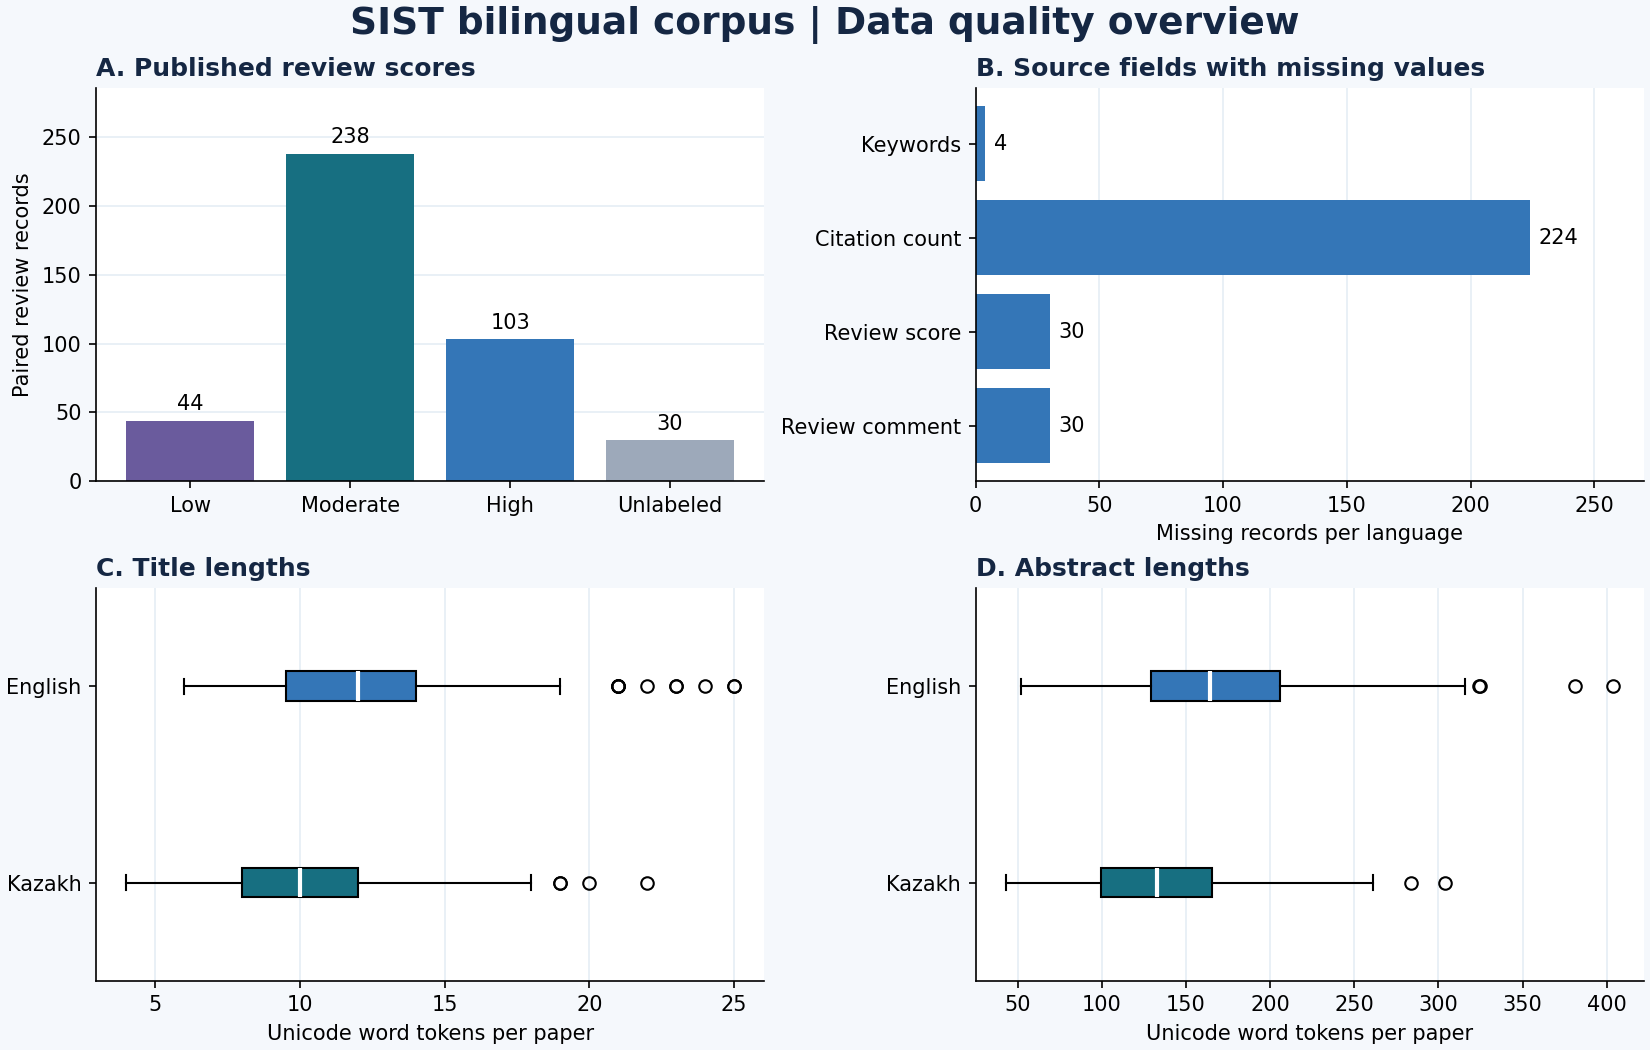

In [5]:
display(length_summary(lengths).round(1))
plot_overview(reviews, lengths, missing)
display(Image(filename=str(FIGURE), width=850))